<a href="https://colab.research.google.com/github/RichardEager0803/Machine-Learning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment #5

Diabetes Classification using Ensemble Learning and Random Forests

Goals:

* Source the UCI Pima Indians Diabetes dataseet
* Inspect the dataset's structure
* Handle missing data
* Construct a preprocessing pipeline using Scikit-Learn
* **Implement ensemble models, including Voting Classifiers, Bagging with Out-of-Bag evaluation, Random Forests, and AdaBoost, to predict the presence of diabetes**

Imports:

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

Task 1 - Loads the dataset into a Pandas DataFrame (called df).

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

df = pd.read_csv(url, header=None, names=column_names)

Task 2 - Uses inspection methods (head(),
info(), and describe()) to analyze features.

In [3]:
print('\nHead Method: ')
print(df.head())

print('\nInfo Method: ')
print(df.info())

print('\nDescribe Method: ')
print(df.describe())


Head Method: 
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Info Method: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1  

Task 3 & 4 - Quantifies and handles any missing or implicit missing values across the columns, and implements a structured imputation strategy using Scikit-Learn's SimpleImputer.
Isolates numerical and categorical features, then applies appropriate scaling to numerical and encoding to categorical columns.

In [4]:
# Task - 3

# Physiological columns where 0 is an invalid placeholder
cols_with_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Quantifies missing values (zeros)
print("\nTask 3: Missing Value Count (Zeros): ")
print((df[cols_with_zeros] == 0).sum())

# Replaces 0s with NaN
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Task - 4

# All eight input features are numeric.
# Median imputation handles the missing values, and standard scaling
# helps scale-sensitive models such as Logistic Regression and SVC.
# The preprocessing is fitted on the training data within each pipeline.
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[("num", numeric_transformer, X.columns)]
)


Task 3: Missing Value Count (Zeros): 
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


Task 5 - Trains a Hard Voting Classifier and a Soft Voting Classifier combining base models. In this case the three models chosen are Logistic Regression, Support Vector Classifier, and a Decision Tree.

The test accuracy and classification reports are then evaluated and plots are used to show the results.


Task 5: Voting Classifier Results: 
Hard Voting Test Accuracy: 0.7338
Soft Voting Test Accuracy: 0.7403

Hard Voting Classification Report: 
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       100
           1       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154


Soft Voting Classification Report: 
              precision    recall  f1-score   support

           0       0.78      0.83      0.81       100
           1       0.65      0.57      0.61        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.71       154
weighted avg       0.73      0.74      0.74       154



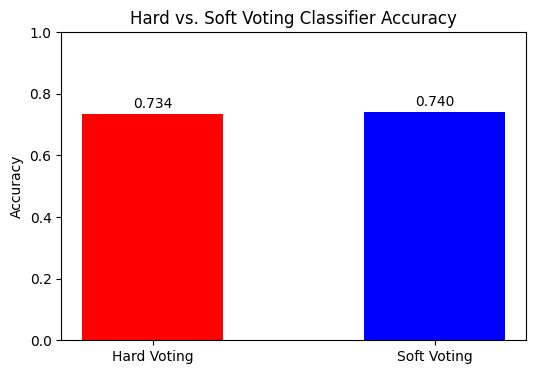

In [5]:
clf1 = LogisticRegression(random_state=42)
clf2 = SVC(probability=True, random_state=42)
clf3 = DecisionTreeClassifier(random_state=42)

hard_voting = VotingClassifier(
    estimators=[("lr", clf1), ("svc", clf2), ("dt", clf3)], voting="hard"
)

soft_voting = VotingClassifier(
    estimators=[("lr", clf1), ("svc", clf2), ("dt", clf3)], voting="soft"
)

# Wraps the preprocessor and classifiers into pipelines
hard_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", hard_voting)]
)
soft_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", soft_voting)]
)

hard_pipeline.fit(X_train, y_train)
soft_pipeline.fit(X_train, y_train)

y_pred_hard = hard_pipeline.predict(X_test)
y_pred_soft = soft_pipeline.predict(X_test)

print(
    "\nTask 5: Voting Classifier Results: "
    f"\nHard Voting Test Accuracy: {accuracy_score(y_test, y_pred_hard):.4f}"
)
print(
    f"Soft Voting Test Accuracy: {accuracy_score(y_test, y_pred_soft):.4f}"
)

print("\nHard Voting Classification Report: ")
print(classification_report(y_test, y_pred_hard, zero_division=0))

print("\nSoft Voting Classification Report: ")
print(classification_report(y_test, y_pred_soft, zero_division=0))

# Plot Voting Results
voting_accs = [
    accuracy_score(y_test, y_pred_hard),
    accuracy_score(y_test, y_pred_soft),
]
plt.figure(figsize=(6, 4))
plt.bar(
    ["Hard Voting", "Soft Voting"],
    voting_accs,
    color=["red", "blue"],
    width=0.5,
)
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
plt.title("Hard vs. Soft Voting Classifier Accuracy")
for i, v in enumerate(voting_accs):
    plt.text(i, v + 0.02, f"{v:.3f}", ha="center")
plt.show()

Task 6 - Trains a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation.

Compares the OOB score against held-out test accuracy. The accuracy results are plotted in one graph.


Task 6: Bagging Classifier: 
OOB Score: 0.7557
Test Accuracy: 0.7208


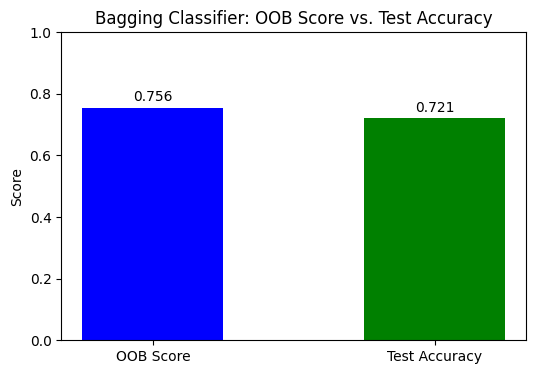

In [6]:
bagging_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "bagging",
            BaggingClassifier(
                estimator=DecisionTreeClassifier(random_state=42),
                n_estimators=100,
                bootstrap=True,
                oob_score=True,
                random_state=42,
            ),
        ),
    ]
)

bagging_pipe.fit(X_train, y_train)
oob_score = bagging_pipe.named_steps["bagging"].oob_score_
test_acc_bagging = accuracy_score(y_test, bagging_pipe.predict(X_test))

print(f"\nTask 6: Bagging Classifier: ")
print(f"OOB Score: {oob_score:.4f}")
print(f"Test Accuracy: {test_acc_bagging:.4f}")

# Plots OOB vs Test Accuracy
plt.figure(figsize=(6, 4))
plt.bar(
    ["OOB Score", "Test Accuracy"],
    [oob_score, test_acc_bagging],
    color=["blue", "green"],
    width=0.5,
)
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.title("Bagging Classifier: OOB Score vs. Test Accuracy")
for i, v in enumerate([oob_score, test_acc_bagging]):
    plt.text(i, v + 0.02, f"{v:.3f}", ha="center")
plt.show()

Task 7 - Trains a Random Forest Classifier configured with feature subsetting, its test performance is evaluated. A horizontal bar plot visualizing feature importances (Mean Decrease in Impurity) is generated below.


Task 7: Random Forest: 
Test Accuracy: 0.7727


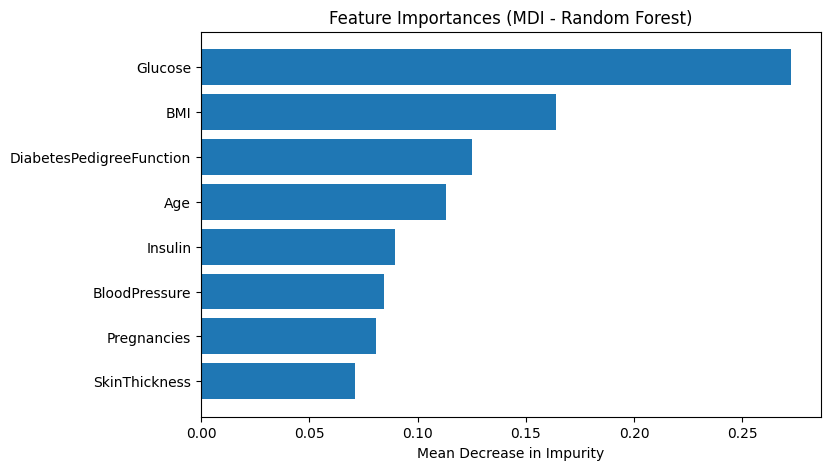

In [7]:
rf_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "rf",
            RandomForestClassifier(
                n_estimators=100, max_features="sqrt", random_state=42
            ),
        ),
    ]
)

rf_pipe.fit(X_train, y_train)
test_acc_rf = accuracy_score(y_test, rf_pipe.predict(X_test))
print(f"\nTask 7: Random Forest: ")
print(f"Test Accuracy: {test_acc_rf:.4f}")

importances = rf_pipe.named_steps["rf"].feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 5))
plt.title("Feature Importances (MDI - Random Forest)")
plt.barh(range(X.shape[1]), importances[indices], align="center")
plt.yticks(range(X.shape[1]), [X.columns[i] for i in indices])
plt.xlabel("Mean Decrease in Impurity")
plt.show()

Task 8 - Trains an AdaBoost Classifier using decision stumps and sequential sample weighting. The training vs test performance is evaluated to observe potential boosting generalization trends. The results are also plotted below.


Task 8: AdaBoost: 
Final Training Accuracy: 0.8143
Final Test Accuracy: 0.7597


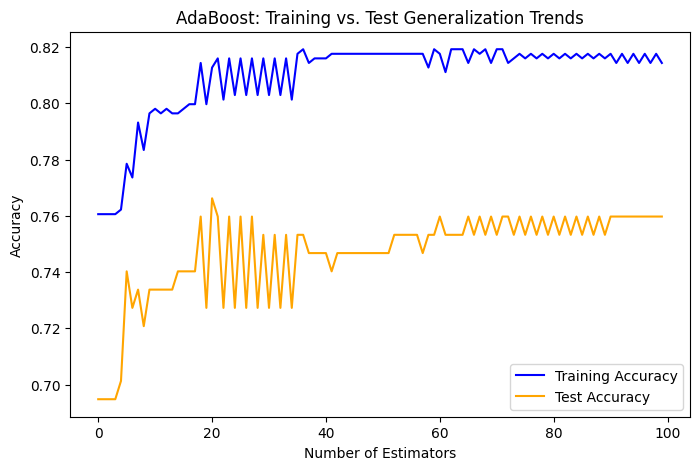

In [8]:
adaboost_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "ada",
            AdaBoostClassifier(
                estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
                n_estimators=100,
                random_state=42,
            ),
        ),
    ]
)

adaboost_pipe.fit(X_train, y_train)

# Evaluates training vs test performance across boosting iterations using staged scoring
X_train_processed = adaboost_pipe.named_steps["preprocessor"].transform(X_train)
X_test_processed = adaboost_pipe.named_steps["preprocessor"].transform(X_test)

ada_model = adaboost_pipe.named_steps["ada"]
train_staged_scores = list(ada_model.staged_score(X_train_processed, y_train))
test_staged_scores = list(ada_model.staged_score(X_test_processed, y_test))

ada_train_accuracy = accuracy_score(
    y_train, adaboost_pipe.predict(X_train)
)

ada_test_accuracy = accuracy_score(
    y_test, adaboost_pipe.predict(X_test)
)

print("\nTask 8: AdaBoost: ")
print(f"Final Training Accuracy: {ada_train_accuracy:.4f}")
print(f"Final Test Accuracy: {ada_test_accuracy:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(train_staged_scores, label="Training Accuracy", color="blue")
plt.plot(test_staged_scores, label="Test Accuracy", color="orange")
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Training vs. Test Generalization Trends")
plt.legend()
plt.show()